# GBHeat | Paper-style figures from saved model results

This notebook reproduces the **original paper notebook's figure code, map dimensions, GB boundary appearance, colour scales, labels and panel layouts**. It reads saved outputs from notebook 01 and the stock-informed LA outputs from notebook 04. It does not rerun the GBHeat model or redistribute demand.

Run the cells top to bottom from the repository. Figures save under `data/outputs/figures/<run_id>/05_GBHeat_Figures/` at 600 dpi.

## 1. Scenario settings — same as notebook 01

In [1]:
# The same four scenario assumptions used in notebook 01
weather_year = 2010
future_year = 2050
FES_year = "2022"
FES_scenario = "LW"

# Stock-informed LA profiles created by notebook 04
LA_ALLOCATION_METHOD = "fes_stock_area"
SELECTED_LA_CODE = "S12000048"

SAVE_FIGURES = True
SHOW_FIGURES = True

SCENARIO = FES_scenario
YEAR = future_year
WEATHER_START_YEAR = weather_year
scenario = SCENARIO
year = YEAR


## 2. Imports, paths and paper-style helpers

In [2]:
# ============================================================
# 1. Imports and configuration
# ============================================================

from pathlib import Path
from glob import glob
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches

from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, Normalize, LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec


# ------------------------------------------------------------
# Analysis settings (configured in the cell above)
# ------------------------------------------------------------
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data").is_dir() and ((p / "notebooks").exists() or (p / "README.md").exists()):
            return p
    raise FileNotFoundError("Open the notebook from within the GBHeatModel repository.")

PROJECT_ROOT = find_root()
DATA_DIR = PROJECT_ROOT / "data"
PROFILE_BASE = DATA_DIR / "outputs" / "heating_profiles"
RUN_ID = f"{weather_year}_{FES_year}_{SCENARIO}_{YEAR}"
PROFILE_DIR = PROFILE_BASE / RUN_ID
SCENARIO_FOLDERS = {SCENARIO: PROFILE_DIR}
scenario_folders = SCENARIO_FOLDERS

GRID_FILE = DATA_DIR / "UK_Atlite_Grid_sq.gpkg"
LA_FILE = DATA_DIR / "LAs_shapefile_2021" / "LAD_DEC_2021_GB_BFC.shp"
LA_PROFILE_DIR = (DATA_DIR / "outputs" / "LA_heat_profiles" / RUN_ID
                  / LA_ALLOCATION_METHOD / "profiles")
OUTPUT_DIR = (DATA_DIR / "outputs" / "figures" / RUN_ID / "05_GBHeat_Figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Scenario: {SCENARIO}")
print(f"Year: {YEAR}")
print(f"Profile folder: {SCENARIO_FOLDERS[SCENARIO]}")
print("Figures:", OUTPUT_DIR)


Scenario: LW
Year: 2050
Profile folder: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050
Figures: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures


In [3]:
# ============================================================
# 2. Core data-loading and aggregation helpers
# ============================================================

_PROFILE_CACHE = {}


def read_hd_profiles_from_folder(folder):
    """
    Read all saved half-hourly grid heat-demand CSV files from one folder.

    Returns
    -------
    dict
        {Grid_ID: DataFrame}
    """
    folder = Path(folder)
    files = sorted(folder.glob("half_hourly_heat_profile_*.csv"))

    if not files:
        raise FileNotFoundError(f"No CSV files found in: {folder}")

    profiles = {}

    for file in files:
        name = file.stem
        grid_id = name.replace("half_hourly_heat_profile_", "")
        parts = grid_id.split("_")
        grid_id = "_".join(parts[:2])

        df = pd.read_csv(file, index_col=0)
        df.index = pd.to_datetime(df.index)
        df = df.apply(pd.to_numeric, errors="raise")
        if df.index.has_duplicates or df.isna().any().any():
            raise ValueError(f"Invalid timestamp or missing values in {file.name}")
        profiles[grid_id] = df.sort_index()

    print(f"Loaded {len(profiles)} grid profiles from {folder}")
    return profiles


def get_scenario_profiles(scenario_name):
    """
    Load a scenario once and reuse it throughout the notebook.
    """
    if scenario_name not in SCENARIO_FOLDERS:
        raise KeyError(
            f"Unknown scenario '{scenario_name}'. "
            f"Available: {list(SCENARIO_FOLDERS)}"
        )

    if scenario_name not in _PROFILE_CACHE:
        _PROFILE_CACHE[scenario_name] = read_hd_profiles_from_folder(
            SCENARIO_FOLDERS[scenario_name]
        )
    else:
        print(f"Using cached {scenario_name} profiles")

    return _PROFILE_CACHE[scenario_name]


def total_grid_series(profiles):
    """
    Convert each grid DataFrame to one total half-hourly kWh Series.
    """
    return {
        grid_id: df.select_dtypes("number").sum(axis=1)
        for grid_id, df in profiles.items()
    }


def national_series_from_profiles(profiles):
    """
    Aggregate all grid and technology profiles to national half-hourly kWh.
    """
    grid_series = total_grid_series(profiles)
    return pd.concat(grid_series, axis=1).sum(axis=1).sort_index()


def annual_grid_summary(profiles):
    """
    Annual heat demand by grid square.
    """
    return pd.DataFrame({
        "Grid_ID": list(profiles.keys()),
        "Annual_Heat_GWh": [
            df.select_dtypes("number").sum().sum() / 1e6
            for df in profiles.values()
        ],
    })


def kwh_hh_to_mw(series):
    """kWh per 30-minute interval -> MW."""
    return series * 2 / 1000


def kwh_hh_to_gw(series):
    """kWh per 30-minute interval -> GW."""
    return series * 2 / 1e6


def save_figure(fig, filename):
    """
    Save paper figures consistently.
    """
    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / filename, dpi=600, bbox_inches=None)
        print("Saved:", OUTPUT_DIR / filename)

In [4]:
# ============================================================
# 3. Load active scenario once
# ============================================================

profiles = get_scenario_profiles(SCENARIO)

# Compatibility alias used in a few analysis cells
profiles_LW = profiles if SCENARIO == "LW" else None

grid_series = total_grid_series(profiles)
gbheat_halfhour = pd.concat(grid_series, axis=1).sum(axis=1).sort_index()
grid_annual = annual_grid_summary(profiles)

print(f"Loaded grids: {len(profiles)}")
print(f"Annual GB heat demand: {gbheat_halfhour.sum() / 1e9:.2f} TWh")
print(f"Half-hourly maximum energy: {gbheat_halfhour.max() / 1e6:.2f} GWh/half-hour")

Loaded 738 grid profiles from C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050
Loaded grids: 738
Annual GB heat demand: 222.77 TWh
Half-hourly maximum energy: 45.94 GWh/half-hour


In [5]:
# ============================================================
# 4. Load and prepare spatial data once
# ============================================================

grid_gdf = gpd.read_file(GRID_FILE)
la_gdf = gpd.read_file(LA_FILE)

grid_gdf["Grid_ID"] = (
    grid_gdf["x"].astype(str)
    + "_"
    + grid_gdf["y"].astype(str)
)

# Keep geometry in its source CRS for reusable joins
la_gdf = la_gdf.to_crs(grid_gdf.crs)

grid_map = grid_gdf.merge(
    grid_annual,
    on="Grid_ID",
    how="left"
)

# Projected copies reused for all spatial overlays/maps
grid_gdf_bng = grid_gdf.to_crs(epsg=27700)
la_gdf_bng = la_gdf.to_crs(epsg=27700)

grid_map_bng = (
    grid_map
    .dropna(subset=["Annual_Heat_GWh"])
    .to_crs(epsg=27700)
    .copy()
)

gb_outline = la_gdf_bng.dissolve()

print(f"Grid geometries: {len(grid_gdf)}")
print(f"Local Authorities: {len(la_gdf)}")

Cannot find header.dxf (GDAL_DATA is not defined)


Grid geometries: 2728
Local Authorities: 363


In [6]:
# ============================================================
# 5. Shared publication map layout
# ============================================================

FIGSIZE_MAP = (8, 10)

LEFT = 0.04
RIGHT = 0.92
BOTTOM = 0.04
TOP = 0.92
MAP_CBAR_WIDTH = [1.0, 0.045]

minx, miny, maxx, maxy = la_gdf_bng.total_bounds
x_pad = (maxx - minx) * 0.025
y_pad = (maxy - miny) * 0.025

GB_XLIM = (minx - x_pad, maxx + x_pad)
GB_YLIM = (miny - y_pad, maxy + y_pad)


def apply_common_map_style(ax):
    ax.set_xlim(GB_XLIM)
    ax.set_ylim(GB_YLIM)
    ax.set_aspect("equal")
    ax.axis("off")


def create_map_with_colorbar_axis():
    fig = plt.figure(figsize=FIGSIZE_MAP)

    gs = gridspec.GridSpec(
        1,
        2,
        figure=fig,
        width_ratios=MAP_CBAR_WIDTH,
        wspace=0.04
    )

    ax = fig.add_subplot(gs[0, 0])
    cax = fig.add_subplot(gs[0, 1])

    fig.subplots_adjust(
        left=LEFT,
        right=RIGHT,
        bottom=BOTTOM,
        top=TOP
    )

    return fig, ax, cax


def create_map_without_colorbar():
    fig = plt.figure(figsize=FIGSIZE_MAP)

    gs = gridspec.GridSpec(
        1,
        2,
        figure=fig,
        width_ratios=MAP_CBAR_WIDTH,
        wspace=0.04
    )

    ax = fig.add_subplot(gs[0, 0])
    blank_ax = fig.add_subplot(gs[0, 1])
    blank_ax.axis("off")

    fig.subplots_adjust(
        left=LEFT,
        right=RIGHT,
        bottom=BOTTOM,
        top=TOP
    )

    return fig, ax

# ============================================================
# Shared publication time-series layout
# ============================================================

FIGSIZE_TS = (18, 7)
FIGSIZE_TS_SINGLE = (12, 7)
TITLE_FONTSIZE = 24
PANEL_TITLE_FONTSIZE = 18
LABEL_FONTSIZE = 18
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 13


def apply_common_timeseries_style(ax):
    """Apply the common journal style used for GBHeat time-series figures."""
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=TICK_FONTSIZE
    )

    ax.grid(
        axis="y",
        alpha=0.25,
        linewidth=0.8
    )
    ax.grid(axis="x", visible=False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


## 3. Existing LA results — full coverage required for the two-panel map

In [7]:
# Notebook 04 output only; no redistribution or FES stock calculations here.
la_files = sorted(LA_PROFILE_DIR.glob("LA_heat_profile_*.csv"))
la_records = []
for file in la_files:
    code_id = file.stem.replace("LA_heat_profile_", "")
    df = pd.read_csv(file, index_col=0)
    df.index = pd.to_datetime(df.index)
    if df.index.has_duplicates or df.isna().any().any():
        raise ValueError(f"Invalid LA profile: {file.name}")
    if "total_thermal_heat_demand" in df.columns:
        annual = pd.to_numeric(df["total_thermal_heat_demand"]).sum() / 1e6
    else:
        annual = df.select_dtypes("number").sum().sum() / 1e6
    la_records.append({"LAD21CD": code_id, "Allocated_Heat_GWh": annual})

la_annual = pd.DataFrame(la_records, columns=["LAD21CD", "Allocated_Heat_GWh"])
expected_las = set(la_gdf["LAD21CD"].astype(str))
found_las = set(la_annual["LAD21CD"])
COMPLETE_LA_COVERAGE = bool(la_files) and found_las == expected_las
print(f"LA files: {len(la_files)}; boundary authorities: {len(expected_las)}")
print(f"Complete LA coverage: {COMPLETE_LA_COVERAGE}")
if not COMPLETE_LA_COVERAGE:
    print("Annual LA-vs-grid comparison will be skipped. "
          "Run notebook 04 for LA_SELECTION='all' to generate all LA files.")
else:
    la_map_stock_weighted = la_gdf_bng.merge(la_annual, on="LAD21CD", how="left")
    total_la = la_annual["Allocated_Heat_GWh"].sum()
    total_grid = grid_annual["Annual_Heat_GWh"].sum()
    if not np.isclose(total_la, total_grid, rtol=1e-6, atol=1e-3):
        raise ValueError(f"LA total {total_la:.6f} GWh != grid total {total_grid:.6f} GWh")


LA files: 1; boundary authorities: 363
Complete LA coverage: False
Annual LA-vs-grid comparison will be skipped. Run notebook 04 for LA_SELECTION='all' to generate all LA files.


## 4. Annual heating demand by Local Authority and weather grid

Uses the exact two-panel map layout from the paper notebook. Skipped when only selected LA profiles have been exported.

In [8]:
if COMPLETE_LA_COVERAGE:
    # ============================================================
    # Figure — Annual domestic heating demand
    # across Local Authority and weather-grid resolutions
    # ============================================================

    def create_two_panel_map_layout(
        figsize=(13.5, 7.2),
        map_cbar_width=(1.0, 0.055),
        panel_wspace=0.08,
        inner_wspace=0.035
    ):
        """
        Create two equal-width publication panels.

        Each panel contains:
            [map axis | colour-bar axis]
        """

        fig = plt.figure(figsize=figsize, facecolor="white")

        outer = GridSpec(
            1,
            2,
            figure=fig,
            wspace=panel_wspace,
            left=0.035,
            right=0.985,
            bottom=0.07,
            top=0.84
        )

        panel_axes = []

        for i in range(2):
            inner = GridSpecFromSubplotSpec(
                1,
                2,
                subplot_spec=outer[0, i],
                width_ratios=map_cbar_width,
                wspace=inner_wspace
            )

            ax = fig.add_subplot(inner[0, 0])
            cax = fig.add_subplot(inner[0, 1])
            panel_axes.append((ax, cax))

        return fig, panel_axes


    # ============================================================
    # Create figure
    # ============================================================

    fig, panel_axes = create_two_panel_map_layout()

    (ax_la, cax_la) = panel_axes[0]
    (ax_grid, cax_grid) = panel_axes[1]

    panel_title_kwargs = dict(
        fontsize=15,
        fontweight="semibold",
        pad=8
    )

    cmap = plt.get_cmap("YlOrRd")


    # ============================================================
    # Check colour-bar scales
    # ============================================================

    la_values = la_map_stock_weighted["Allocated_Heat_GWh"].dropna()
    grid_values = grid_map_bng["Annual_Heat_GWh"].dropna()

    print("LA annual heat demand statistics (GWh)")
    print(la_values.describe(percentiles=[0.02, 0.25, 0.50, 0.75, 0.98]))

    print("\nWeather-grid annual heat demand statistics (GWh)")
    print(grid_values.describe(percentiles=[0.02, 0.25, 0.50, 0.75, 0.98]))


    # Use robust clipping to avoid one or two extreme values dominating the colour scale
    la_vmin = la_values.quantile(0.02)
    la_vmax = la_values.quantile(0.98)

    grid_vmin = grid_values.quantile(0.02)
    grid_vmax = grid_values.quantile(0.98)


    # ============================================================
    # Panel (a) — Local Authority resolution
    # ============================================================

    la_map_stock_weighted.plot(
        column="Allocated_Heat_GWh",
        cmap=cmap,
        linewidth=0.15,
        edgecolor="grey",
        vmin=la_vmin,
        vmax=la_vmax,
        missing_kwds={
            "color": "white",
            "edgecolor": "lightgrey"
        },
        ax=ax_la
    )

    la_sm = ScalarMappable(
        cmap=cmap,
        norm=Normalize(vmin=la_vmin, vmax=la_vmax)
    )
    la_sm.set_array([])

    la_cbar = fig.colorbar(la_sm, cax=cax_la)
    la_cbar.set_label("Annual heating demand (GWh)", fontsize=14, labelpad=9)
    la_cbar.ax.tick_params(labelsize=12, width=0.7, length=3.5, direction="out")
    la_cbar.outline.set_linewidth(0.7)

    apply_common_map_style(ax_la)

    ax_la.set_title(
        "(a) Local Authority resolution",
        **panel_title_kwargs
    )


    # ============================================================
    # Panel (b) — Weather-grid resolution
    # ============================================================

    grid_map_bng.plot(
        column="Annual_Heat_GWh",
        cmap=cmap,
        linewidth=0.20,
        edgecolor="white",
        vmin=grid_vmin,
        vmax=grid_vmax,
        ax=ax_grid
    )

    gb_outline.boundary.plot(
        ax=ax_grid,
        linewidth=0.8,
        edgecolor="black"
    )

    grid_sm = ScalarMappable(
        cmap=cmap,
        norm=Normalize(vmin=grid_vmin, vmax=grid_vmax)
    )
    grid_sm.set_array([])

    grid_cbar = fig.colorbar(grid_sm, cax=cax_grid)
    grid_cbar.set_label("Annual heating demand (GWh)", fontsize=14, labelpad=9)
    grid_cbar.ax.tick_params(labelsize=12, width=0.7, length=3.5, direction="out")
    grid_cbar.outline.set_linewidth(0.7)

    apply_common_map_style(ax_grid)

    ax_grid.set_title(
        "(b) Weather-grid resolution",
        **panel_title_kwargs
    )


    # ============================================================
    # Common figure title
    # ============================================================

    fig.suptitle(
        f"Annual Domestic Heating Demand by Spatial Resolution ({SCENARIO}, {YEAR})",
        fontsize=19,
        fontweight="semibold",
        y=0.965
    )


    # ============================================================
    # Save
    # ============================================================

    save_figure(
        fig,
        (
            "Figure_Comparison_of_Heat_Demand_LA_and_"
            f"Weather_Grid_{SCENARIO}_{YEAR}.png"
        )
    )

    plt.show()
else:
    print('Skipped: annual LA-grid map requires complete LA profiles from notebook 04.')


Skipped: annual LA-grid map requires complete LA profiles from notebook 04.


## 5. Local peak timing vs the GB coincident peak

In [9]:
# ============================================================
# Peak-demand metrics by spatial resolution
# ============================================================


# -------------------------------
# 1. Grid-square half-hourly totals
# -------------------------------
grid_peak_records = []

grid_series = {}

for grid_id, df in profiles.items():
    s = df.sum(axis=1) / 1e6   # kWh per half-hour -> GWh per half-hour
    grid_series[grid_id] = s

    peak_time = s.idxmax()
    peak_value_gwh = s.max()

    grid_peak_records.append({
        "Grid_ID": grid_id,
        "Peak_Demand_GWh_per_hh": peak_value_gwh,
        "Peak_Time": peak_time,
        "Peak_Day": peak_time.date(),
        "Peak_Hour": peak_time.hour + peak_time.minute / 60
    })

grid_peak = pd.DataFrame(grid_peak_records)

# -------------------------------
# 2. National profile and peak
# -------------------------------
national_series = sum(grid_series.values())

national_peak_time = national_series.idxmax()
national_peak_gwh = national_series.max()

print("National peak time:", national_peak_time)
print("National peak demand:", national_peak_gwh, "GWh per half-hour")

# -------------------------------
# 3. Diversity factor
# -------------------------------
sum_grid_peaks = grid_peak["Peak_Demand_GWh_per_hh"].sum()

diversity_factor = sum_grid_peaks / national_peak_gwh

print("Sum of individual grid peaks:", sum_grid_peaks, "GWh per half-hour")
print("Coincident national peak:", national_peak_gwh, "GWh per half-hour")
print("Peak diversity factor:", diversity_factor)

National peak time: 2050-12-20 07:30:00
National peak demand: 45.9413119090483 GWh per half-hour
Sum of individual grid peaks: 49.11511038041086 GWh per half-hour
Coincident national peak: 45.9413119090483 GWh per half-hour
Peak diversity factor: 1.069083757939822


Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures\Figure_full_year_temporal_separation_local_peaks_GB_peak_LW_2050.png


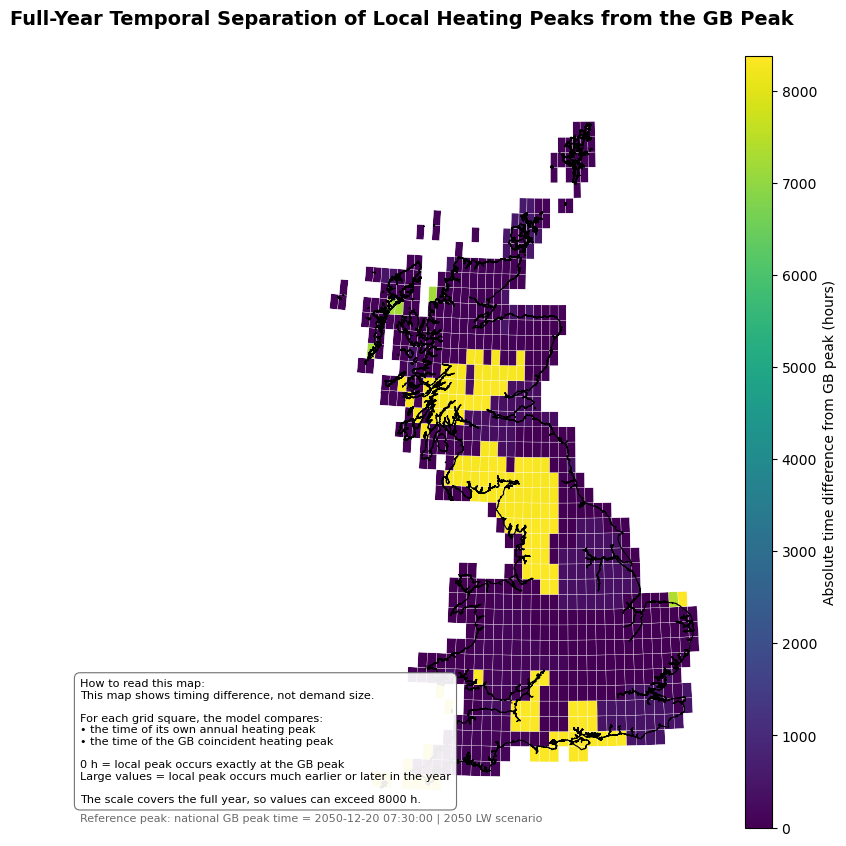

In [10]:
# ============================================================
# Figure — Full-year temporal separation between local grid peaks
#          and the GB coincident heating peak
# ============================================================


# ------------------------------------------------------------
# 1. Calculate timing difference from national GB peak
# ------------------------------------------------------------
grid_peak = grid_peak.copy()

grid_peak["Hours_From_National_Peak"] = (
    (grid_peak["Peak_Time"] - national_peak_time)
    .dt.total_seconds()
    / 3600
)

grid_peak["Abs_Hours_From_National_Peak"] = (
    grid_peak["Hours_From_National_Peak"].abs()
)

# ------------------------------------------------------------
# 2. Merge timing values with grid geometries
# ------------------------------------------------------------
grid_peak_map = grid_gdf.merge(
    grid_peak,
    on="Grid_ID",
    how="left"
)

grid_peak_map = grid_peak_map.to_crs(epsg=27700)
gb_outline = la_gdf.to_crs(epsg=27700).dissolve()

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 10))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)

grid_peak_map.plot(
    column="Abs_Hours_From_National_Peak",
    cmap="viridis",
    linewidth=0.2,
    edgecolor="white",
    legend=True,
    cax=cax,
    missing_kwds={"color": "white", "label": "No data"},
    legend_kwds={
        "label": "Absolute time difference from GB peak (hours)"
    },
    ax=ax
)

gb_outline.boundary.plot(
    ax=ax,
    linewidth=0.8,
    edgecolor="black"
)

# ------------------------------------------------------------
# 4. Title and interpretation box
# ------------------------------------------------------------
ax.set_title(
    "Full-Year Temporal Separation of Local Heating Peaks from the GB Peak",
    fontsize=14,
    fontweight="bold",
    pad=12
)

description = (
    "How to read this map:\n"
    "This map shows timing difference, not demand size.\n\n"
    "For each grid square, the model compares:\n"
    "• the time of its own annual heating peak\n"
    "• the time of the GB coincident heating peak\n\n"
    "0 h = local peak occurs exactly at the GB peak\n"
    "Large values = local peak occurs much earlier or later in the year\n\n"
    "The scale covers the full year, so values can exceed 8000 h."
)

ax.text(
    0.02,
    0.03,
    description,
    transform=ax.transAxes,
    fontsize=8.1,
    color="black",
    va="bottom",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.4",
        linewidth=0.8,
        alpha=0.92
    )
)

ax.text(
    0.02,
    0.005,
    f"Reference peak: national GB peak time = {national_peak_time} | {YEAR} {scenario} scenario",
    transform=ax.transAxes,
    fontsize=8,
    color="dimgray",
    va="bottom"
)

# ------------------------------------------------------------
# 5. Formatting and save
# ------------------------------------------------------------
ax.axis("off")
ax.set_aspect("equal")

plt.tight_layout()


save_figure(fig, f"Figure_full_year_temporal_separation_local_peaks_GB_peak_{scenario}_{YEAR}.png")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## 6. Peak heat demand by Atlite grid square

In [11]:
# ============================================================
# Prepare grid-level annual, peak, and GB peak metrics
# ============================================================

grid_metrics = []

grid_series = {}

for gid, df in profiles.items():
    s_kwh = df.sum(axis=1)          # total heat demand per half-hour, kWh
    grid_series[gid] = s_kwh

    peak_time = s_kwh.idxmax()
    peak_kwh = s_kwh.max()

    grid_metrics.append({
        "Grid_ID": gid,
        "Annual_Heat_GWh": s_kwh.sum() / 1e6,
        "Peak_Heat_MW": peak_kwh * 2 / 1000,   # kWh per 30 min -> MW
        "Peak_Time": peak_time
    })

grid_peak_df = pd.DataFrame(grid_metrics)

# National GB profile
gb_profile_kwh = sum(grid_series.values())

gb_peak_time = gb_profile_kwh.idxmax()
gb_peak_day = gb_peak_time.normalize()
gb_peak_mw = gb_profile_kwh.max() * 2 / 1000

print("GB peak time:", gb_peak_time)
print("GB peak demand:", gb_peak_mw / 1000, "GW")

# Demand in each grid at GB peak
grid_peak_df["Demand_at_GB_Peak_MW"] = [
    grid_series[gid].loc[gb_peak_time] * 2 / 1000
    for gid in grid_peak_df["Grid_ID"]
]

grid_peak_df["Coincidence_Ratio"] = (
    grid_peak_df["Demand_at_GB_Peak_MW"] /
    grid_peak_df["Peak_Heat_MW"]
)

grid_peak_df["Coincidence_Ratio"] = grid_peak_df["Coincidence_Ratio"].clip(0, 1)

GB peak time: 2050-12-20 07:30:00
GB peak demand: 91.8826238180966 GW


Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures\Figure_6_peak_heating_demand_grid_square_LW_2050.png


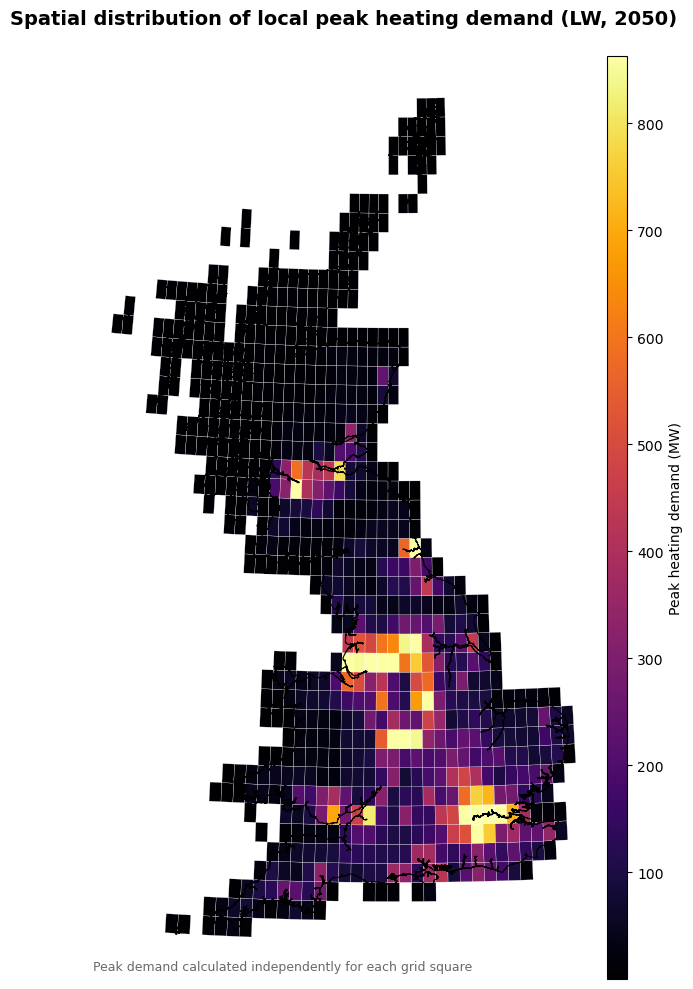

In [12]:
# ============================================================
# Figure 6 — Peak heating demand by Atlite grid square
# Where do the largest local heating peaks occur across Great Britain?
# this figure shows how large that maximum demand is.
# it directly supports one of the central contributions of GBHeat: capturing spatial heterogeneity in peak heating demand.
# ============================================================

peak_map = grid_gdf.merge(
    grid_peak_df[["Grid_ID", "Peak_Heat_MW"]],
    on="Grid_ID",
    how="left"
)

peak_map = peak_map.dropna(subset=["Peak_Heat_MW"]).to_crs(epsg=27700)
gb_outline = la_gdf.to_crs(epsg=27700).dissolve()

fig, ax = plt.subplots(figsize=(8, 10))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="4%", pad=0.08)

vmin = peak_map["Peak_Heat_MW"].quantile(0.02)
vmax = peak_map["Peak_Heat_MW"].quantile(0.98)

peak_map.plot(
    column="Peak_Heat_MW",
    cmap="inferno",
    linewidth=0.18,
    edgecolor="white",
    legend=True,
    cax=cax,
    vmin=vmin,
    vmax=vmax,
    legend_kwds={"label": "Peak heating demand (MW)"},
    ax=ax
)

gb_outline.boundary.plot(
    ax=ax,
    linewidth=0.8,
    edgecolor="black"
)

ax.set_title(
    f"Spatial distribution of local peak heating demand ({scenario}, {YEAR})",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.text(
    0.01,
    0.01,
    "Peak demand calculated independently for each grid square",
    transform=ax.transAxes,
    fontsize=9,
    color="dimgray"
)

ax.axis("off")
ax.set_aspect("equal")

plt.tight_layout()
save_figure(fig, f"Figure_6_peak_heating_demand_grid_square_{scenario}_{YEAR}.png")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## 7. Spatial snapshots around the national GB peak

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures\Figure_peak_day_spatial_snapshots_LW_2050.png


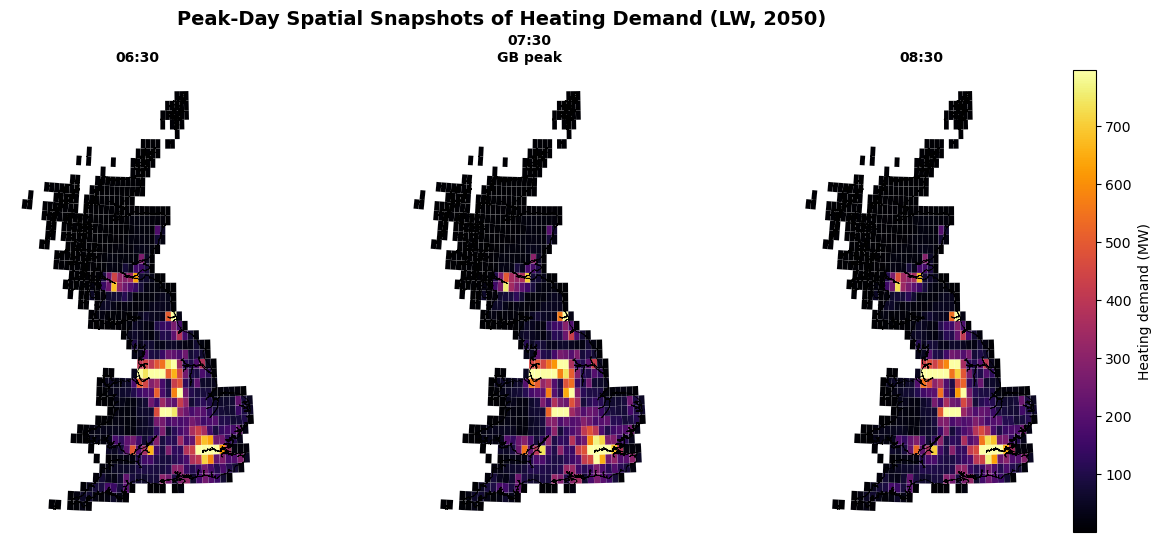

In [13]:
# ============================================================
# Peak-day spatial snapshots around national GB peak
# How does the spatial distribution of heating demand evolve immediately before, during, and after the GB national peak?
# ============================================================

snapshot_times = [
    # gb_peak_time - pd.Timedelta(hours=2),
    gb_peak_time - pd.Timedelta(hours=1),
    gb_peak_time,
    gb_peak_time + pd.Timedelta(hours=1),
    # gb_peak_time + pd.Timedelta(hours=2),
]

snapshot_records = []

for t in snapshot_times:
    for gid, s in grid_series.items():
        snapshot_records.append({
            "Grid_ID": gid,
            "Time": t,
            "Heat_MW": s.loc[t] * 2 / 1000
        })

snapshot_df = pd.DataFrame(snapshot_records)

vmin = snapshot_df["Heat_MW"].quantile(0.02)
vmax = snapshot_df["Heat_MW"].quantile(0.98)

fig, axes = plt.subplots(1, len(snapshot_times), figsize=(15, 6))
# fig = plt.figure(figsize=(16,6))

# gs = fig.add_gridspec(
#     1, 3,
#     width_ratios=[1, 1.35, 1],   # larger middle panel
#     wspace=0.08
# )

# axes = [
#     fig.add_subplot(gs[0]),
#     fig.add_subplot(gs[1]),
#     fig.add_subplot(gs[2])
# ]

for ax, t in zip(axes, snapshot_times):
    temp = snapshot_df[snapshot_df["Time"] == t]

    snap_map = grid_gdf.merge(
        temp[["Grid_ID", "Heat_MW"]],
        on="Grid_ID",
        how="left"
    )

    snap_map = snap_map.dropna(subset=["Heat_MW"]).to_crs(epsg=27700)

    snap_map.plot(
        column="Heat_MW",
        cmap="inferno",
        linewidth=0.05,
        edgecolor="white",
        vmin=vmin,
        vmax=vmax,
        ax=ax
    )

    gb_outline.boundary.plot(
        ax=ax,
        linewidth=0.5,
        edgecolor="black"
    )

    title = t.strftime("%H:%M")
    if t == gb_peak_time:
        title += "\nGB peak"

    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.axis("off")
    ax.set_aspect("equal")

# shared colour bar
sm = ScalarMappable(
    cmap="inferno",
    norm=Normalize(vmin=vmin, vmax=vmax)
)
sm._A = []

cbar = fig.colorbar(
    sm,
    ax=axes,
    fraction=0.025,
    pad=0.02
)
cbar.set_label("Heating demand (MW)")

fig.suptitle(
    f"Peak-Day Spatial Snapshots of Heating Demand ({scenario}, {YEAR})",
    fontsize=14,
    fontweight="bold",
    y=0.98
)

save_figure(fig, f"Figure_peak_day_spatial_snapshots_{scenario}_{YEAR}.png")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## 8. Local-peak versus GB coincident-peak concentration

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures\Figure_combined_local_peak_vs_GB_coincident_peak_concentration_LW_2050.png


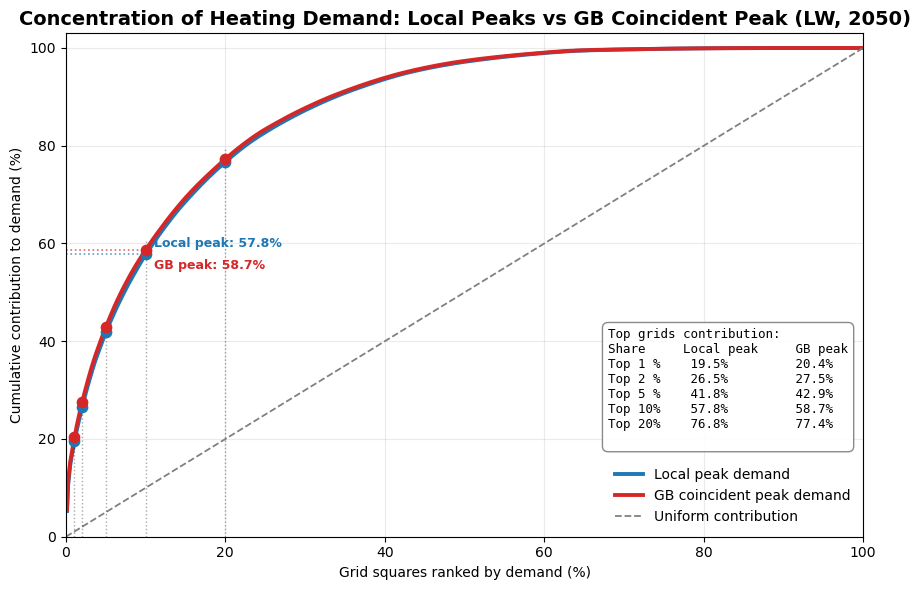

In [14]:
# ============================================================
# Combined figure — Local peak concentration vs GB coincident peak concentration
# ============================================================


# ------------------------------------------------------------
# 1. Local peak concentration
#    Ranking by each grid square's own annual peak
# ------------------------------------------------------------
local_peak_conc = grid_peak_df.copy()

local_peak_conc = local_peak_conc.sort_values(
    "Peak_Heat_MW",
    ascending=False
).reset_index(drop=True)

local_values = local_peak_conc["Peak_Heat_MW"].values
local_cum_percent = np.cumsum(local_values) / np.sum(local_values) * 100
local_x_percent = np.arange(1, len(local_values) + 1) / len(local_values) * 100


# ------------------------------------------------------------
# 2. GB coincident peak concentration
#    Ranking by demand at the GB peak time
# ------------------------------------------------------------
gb_peak_conc = grid_peak_df.copy()

# Use this column if your dataframe already has demand at GB peak
gb_peak_conc = gb_peak_conc.sort_values(
    "Demand_at_GB_Peak_MW",
    ascending=False
).reset_index(drop=True)

gb_values = gb_peak_conc["Demand_at_GB_Peak_MW"].values
gb_cum_percent = np.cumsum(gb_values) / np.sum(gb_values) * 100
gb_x_percent = np.arange(1, len(gb_values) + 1) / len(gb_values) * 100


# ------------------------------------------------------------
# 3. Marker values for summary
# ------------------------------------------------------------
marker_percents = [1, 2, 5, 10, 20]

summary_rows = []

for p in marker_percents:
    n_local = int(np.ceil(len(local_values) * p / 100))
    n_gb = int(np.ceil(len(gb_values) * p / 100))

    local_y = local_cum_percent[n_local - 1]
    gb_y = gb_cum_percent[n_gb - 1]

    summary_rows.append((p, local_y, gb_y))


# ------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    local_x_percent,
    local_cum_percent,
    linewidth=2.8,
    color="#1f77b4",
    label="Local peak demand"
)

ax.plot(
    gb_x_percent,
    gb_cum_percent,
    linewidth=2.8,
    color="#d62728",
    label="GB coincident peak demand"
)

# Uniform contribution line
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    linewidth=1.3,
    color="grey",
    label="Uniform contribution"
)

# ------------------------------------------------------------
# 5. Add markers and guide lines
# ------------------------------------------------------------
for p, local_y, gb_y in summary_rows:

    ax.scatter(
        p,
        local_y,
        s=55,
        color="#1f77b4",
        zorder=5
    )

    ax.scatter(
        p,
        gb_y,
        s=55,
        color="#d62728",
        zorder=5
    )

    ax.axvline(
        p,
        ymin=0,
        ymax=max(local_y, gb_y) / 100,
        linestyle=":",
        linewidth=1,
        color="black",
        alpha=0.35
    )

# Optional: highlight Top 10% only with horizontal guide lines
top10 = [row for row in summary_rows if row[0] == 10][0]
_, local_top10, gb_top10 = top10

ax.axhline(
    local_top10,
    xmin=0,
    xmax=10 / 100,
    linestyle=":",
    linewidth=1.2,
    color="#1f77b4",
    alpha=0.7
)

ax.axhline(
    gb_top10,
    xmin=0,
    xmax=10 / 100,
    linestyle=":",
    linewidth=1.2,
    color="#d62728",
    alpha=0.7
)

ax.text(
    11,
    local_top10 + 1.5,
    f"Local peak: {local_top10:.1f}%",
    fontsize=9,
    fontweight="bold",
    color="#1f77b4"
)

ax.text(
    11,
    gb_top10 - 4,
    f"GB peak: {gb_top10:.1f}%",
    fontsize=9,
    fontweight="bold",
    color="#d62728"
)


## ------------------------------------------------------------
# 6. Summary textbox
# ------------------------------------------------------------
summary_text = "Top grids contribution:\n"
summary_text += "Share     Local peak     GB peak\n"

for p, local_y, gb_y in summary_rows:
    summary_text += f"Top {p:<2}%   {local_y:>5.1f}%        {gb_y:>5.1f}%\n"

# Place textbox in the bottom-right corner (above the legend)
ax.text(
    0.68,          # horizontal position (0 = left, 1 = right)
    0.18,          # vertical position (0 = bottom, 1 = top)
    summary_text,
    transform=ax.transAxes,
    fontsize=9,
    va="bottom",
    ha="left",
    family="monospace",
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="white",
        edgecolor="grey",
        alpha=0.92
    )
)

# ------------------------------------------------------------
# 7. Titles and formatting
# ------------------------------------------------------------
ax.set_title(
    f"Concentration of Heating Demand: Local Peaks vs GB Coincident Peak ({scenario}, {YEAR})",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Grid squares ranked by demand (%)")
ax.set_ylabel("Cumulative contribution to demand (%)")

ax.set_xlim(0, 100)
ax.set_ylim(0, 103)

ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()


save_figure(fig, f"Figure_combined_local_peak_vs_GB_coincident_peak_concentration_{scenario}_{YEAR}.png")
if SHOW_FIGURES:
    plt.show()
else:
    plt.close(fig)

## 9. National thermal demand by heating technology

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\05_GBHeat_Figures\Figure_national_heat_demand_by_technology_LW_2050.png


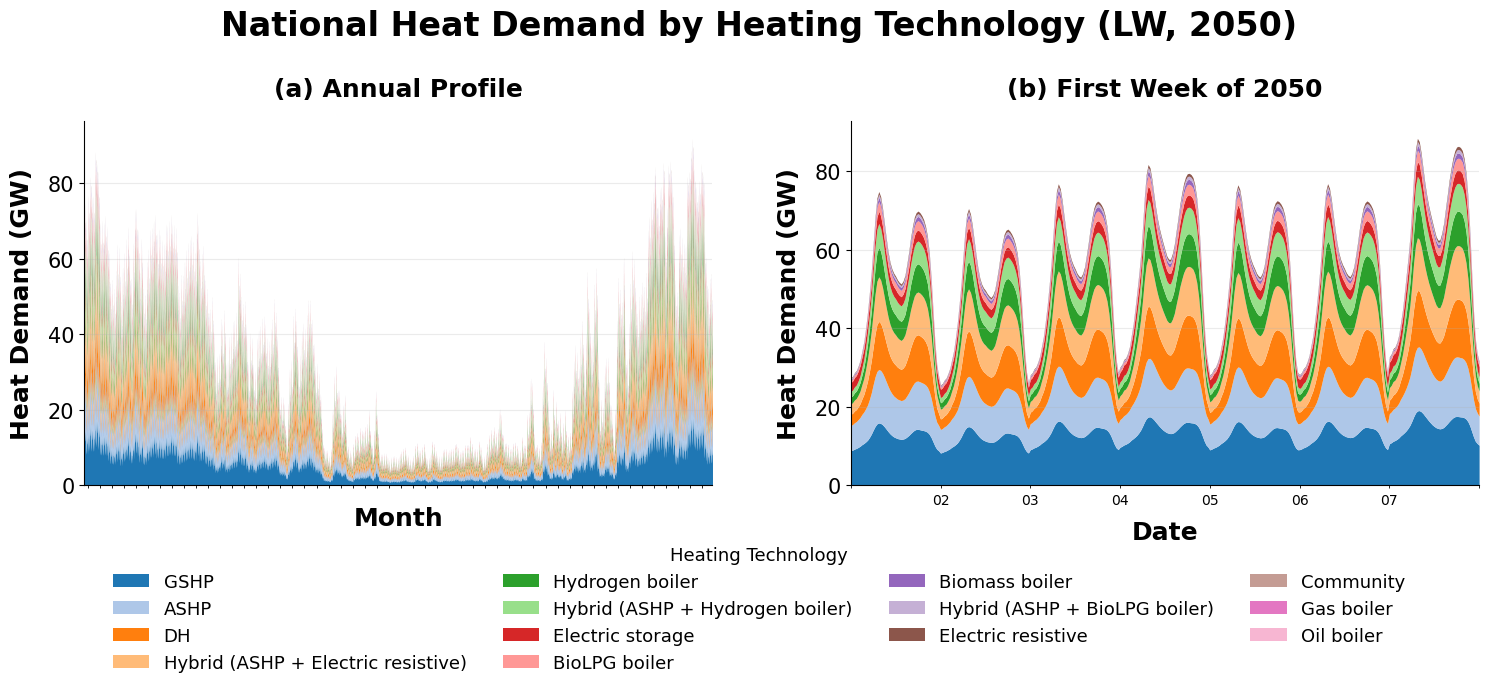

In [15]:
# ============================================================
# Figure — National heat demand by heating technology
# Consistent with the publication style used throughout notebook
# ============================================================

import matplotlib.dates as mdates


def national_technology_profile_gw(profiles):
    """
    Aggregate all grid-cell technology profiles to national demand.

    Input values are kWh per half-hour. The returned DataFrame is
    average GW during each half-hour interval.
    """
    frames = []

    for grid_id, df in profiles.items():
        numeric = df.select_dtypes("number").copy()
        numeric.index = pd.to_datetime(numeric.index)
        frames.append(numeric)

    if not frames:
        raise ValueError("No numeric technology profiles were found.")

    # Sum matching technology columns across all weather-grid cells.
    national = pd.concat(frames).groupby(level=0).sum().sort_index()

    # kWh per 30-min interval -> average GW.
    return national * 2 / 1e6


hd_df = national_technology_profile_gw(profiles)

# Keep the technology order identical in both panels/figures.
technology_order = hd_df.sum().sort_values(ascending=False).index
hd_df = hd_df.loc[:, technology_order]

# Use one fixed colour mapping so each technology keeps the same colour.
tab20 = plt.get_cmap("tab20")
technology_colors = {
    tech: tab20(i % 20)
    for i, tech in enumerate(technology_order)
}
area_colors = [technology_colors[col] for col in hd_df.columns]


# ============================================================
# Panel (a): full-year profile
# Panel (b): first week of 2050
# ============================================================

week_df = hd_df.loc[
    f"{YEAR}-01-01 00:00:00":
    f"{YEAR}-01-08 00:00:00"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=FIGSIZE_TS
)

ax1, ax2 = axes

# ------------------------------------------------------------
# (a) Full year
# ------------------------------------------------------------

hd_df.plot.area(
    ax=ax1,
    stacked=True,
    color=area_colors,
    linewidth=0
)

ax1.set_title(
    "(a) Annual Profile",
    fontsize=PANEL_TITLE_FONTSIZE,
    fontweight="bold",
    pad=18
)

ax1.set_xlabel(
    "Month",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
    labelpad=10
)

ax1.set_ylabel(
    "Heat Demand (GW)",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
    labelpad=10
)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))


# ------------------------------------------------------------
# (b) First week
# ------------------------------------------------------------

week_df.plot.area(
    ax=ax2,
    stacked=True,
    color=area_colors,
    linewidth=0
)

ax2.set_title(
    f"(b) First Week of {YEAR}",
    fontsize=PANEL_TITLE_FONTSIZE,
    fontweight="bold",
    pad=18
)

ax2.set_xlabel(
    "Date",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
    labelpad=10
)

ax2.set_ylabel(
    "Heat Demand (GW)",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
    labelpad=10
)

ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))


# ============================================================
# Common paper styling
# ============================================================

for ax in axes:
    apply_common_timeseries_style(ax)

    # Remove the automatically generated in-panel legends.
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()


# One shared legend below both panels.
handles, labels = ax1.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Heating Technology",
    frameon=False,
    fontsize=LEGEND_FONTSIZE,
    title_fontsize=LEGEND_FONTSIZE,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4
)

fig.suptitle(
    f"National Heat Demand by Heating Technology ({SCENARIO}, {YEAR})",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.30,
    wspace=0.22
)

save_figure(
    fig,
    f"Figure_national_heat_demand_by_technology_{SCENARIO}_{YEAR}.png"
)

plt.show()


## Interpretation

- Annual LA maps use the saved **`fes_stock_area`** redistribution from notebook 04, not a new calculation.
- Local grid peaks occur at each grid's own annual maximum; coincident contributions are evaluated at the GB peak timestep.
- CSV values are **kWh per half-hour**, converted to GW as `2 / 1e6` and to MW as `2 / 1000`.
- Compare all generated figures visually with the source paper notebook before release.
